# Traffic Volume Prediction
UCI Metro Interstate Traffic Volume (I-94, Minneapolis–St Paul). Goal: predict hourly vehicle count from weather and time.

In [1]:
import os, sys, warnings; warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebook": os.chdir("..")   # run from the project root
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import mean_absolute_error, r2_score
from train import load, FEATURES, level, evaluate
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
raw = pd.read_csv("dataset/Metro_Interstate_Traffic_Volume.csv.gz")
print("raw rows:", len(raw))
print("holiday non-null:", raw.holiday.notna().sum(), "-> df.dropna() would leave", len(raw.dropna()), "rows (the original bug)")

raw rows: 48204
holiday non-null: 61 -> df.dropna() would leave 61 rows (the original bug)


## Cleaning
- `holiday` is only filled on holidays, so it becomes a binary feature instead of being dropped with `dropna()`.
- 10 rows have `temp = 0` K (sensor errors) and one `rain_1h` outlier is 9,831 mm.
- Duplicate timestamps (several weather rows per hour) are collapsed to one row.

In [2]:
df = load(); print("rows after cleaning:", len(df)); df[FEATURES + ["traffic_volume"]].describe().T.round(1)

rows after cleaning: 40565


,count,mean,std,min,25%,50%,75%,max
temp,40565.0,281.4,13.1,243.4,271.8,282.9,292.3,310.1
rain_1h,40565.0,0.1,0.7,0.0,0.0,0.0,0.0,28.6
snow_1h,40565.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5
clouds_all,40565.0,44.2,38.7,0.0,1.0,40.0,90.0,100.0
hour,40565.0,11.5,6.9,0.0,5.0,12.0,18.0,23.0
day,40565.0,15.7,8.8,1.0,8.0,16.0,23.0,31.0
month,40565.0,6.5,3.4,1.0,4.0,7.0,9.0,12.0
day_of_week,40565.0,3.0,2.0,0.0,1.0,3.0,5.0,6.0
is_holiday,40565.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
traffic_volume,40565.0,3291.1,1984.6,0.0,1250.0,3429.0,4952.0,7280.0


## What drives traffic?

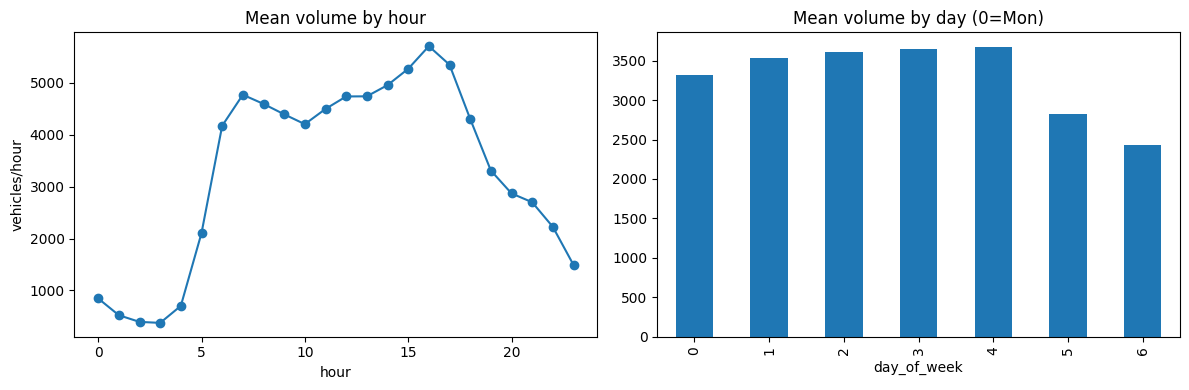

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("hour").traffic_volume.mean().plot(ax=ax[0], marker="o"); ax[0].set(title="Mean volume by hour", ylabel="vehicles/hour")
df.groupby("day_of_week").traffic_volume.mean().plot.bar(ax=ax[1]); ax[1].set(title="Mean volume by day (0=Mon)")
plt.tight_layout(); plt.show()

## Chronological train/test split
Hourly data is autocorrelated, so a random split leaks neighbouring hours into the test set. The first 80% of time trains the model and the last 20% tests it.

In [4]:
n = int(len(df) * 0.8); tr, te = df.iloc[:n], df.iloc[n:]
print("train", tr.date_time.min().date(), "->", tr.date_time.max().date())
print("test ", te.date_time.min().date(), "->", te.date_time.max().date())

train 2012-10-02 -> 2017-10-26
test  2017-10-26 -> 2018-09-30


## Models vs baselines

In [5]:
models = {"Mean baseline": DummyRegressor(), "Linear Regression": LinearRegression(),
          "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=10, random_state=42, n_jobs=-1)}
res = pd.DataFrame({k: evaluate(m, tr, te) for k, m in models.items()}).T.round(3); res

,MAE,R2,level_acc
Mean baseline,1724.119,-0.000,0.287
Linear Regression,1585.391,0.160,0.245
Random Forest,251.751,0.949,0.930


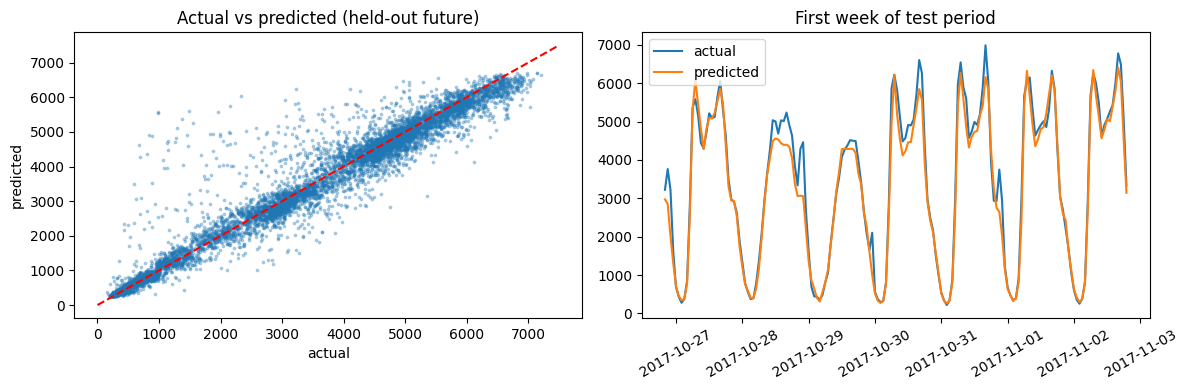

In [6]:
rf = models["Random Forest"]; pred = rf.predict(te[FEATURES])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(te.traffic_volume, pred, s=3, alpha=.3); ax[0].plot([0, 7500], [0, 7500], "r--")
ax[0].set(xlabel="actual", ylabel="predicted", title="Actual vs predicted (held-out future)")
w = te.iloc[:24*7]; ax[1].plot(w.date_time, w.traffic_volume, label="actual"); ax[1].plot(w.date_time, rf.predict(w[FEATURES]), label="predicted")
ax[1].legend(); ax[1].set_title("First week of test period"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

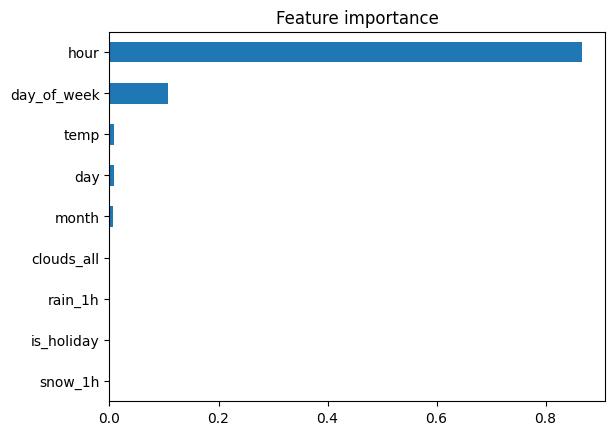

In [7]:
pd.Series(rf.feature_importances_, FEATURES).sort_values().plot.barh(title="Feature importance"); plt.show()

## Findings
- Random Forest cuts MAE from ~1,724 (mean baseline) to ~252 vehicles/hour and reaches R² ≈ 0.95 on unseen future data.
- Linear regression fails (R² ≈ 0.16) because rush-hour demand is non-linear in `hour`.
- Hour of day (~87%) and day of week (~11%) dominate. Weather adds little here, so the app should not be oversold as a weather model.
- The Low/Moderate/Heavy level (<1500, <4000, ≥4000) is matched ~93% of the time.

Run `python train.py` to retrain and save `model/traffic_model.pkl`.